[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sdkfjuecsec/nn-zero-to-hero/blob/my-playground/lectures/makemore/makemore_part2_mlp.ipynb)

In [36]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [37]:
# read in all the words
words = open('../../makemore/names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [38]:
len(words)

32033

In [39]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [ ]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [41]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [42]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:
    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [43]:
C = torch.randn((27, 2))

In [44]:
# C: embedding table with one learned 2-d vector per character, shape (27, 2)
# X: integer character indices, shape (N, 3) for a 3-char context window
# C[X] gathers rows: result shape = X.shape + C.shape[1:] = (N, 3, 2)
# Equivalent to one_hot(X) @ C, but without materializing the one-hot matrix
emb = C[X]
emb.shape  # torch.Size([N, 3, 2])

torch.Size([228146, 3, 2])

In [45]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [46]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [47]:
h

tensor([[-1.0000,  0.9940,  1.0000,  ..., -1.0000,  0.9957,  0.1550],
        [-1.0000,  0.9560,  0.9998,  ..., -1.0000,  0.9539,  0.9951],
        [-1.0000,  0.1960,  0.6441,  ..., -1.0000, -1.0000, -0.9611],
        ...,
        [ 0.9829, -0.9584, -0.9821,  ...,  1.0000, -0.4960,  0.9293],
        [ 0.9817, -0.4038, -0.9894,  ...,  1.0000, -0.9353, -0.2134],
        [ 1.0000, -0.9629, -0.6269,  ..., -0.9653, -0.8612, -1.0000]])

In [48]:
h.shape

torch.Size([228146, 100])

In [49]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [50]:
logits = h @ W2 + b2

In [51]:
logits.shape

torch.Size([228146, 27])

In [52]:
counts = logits.exp()

In [53]:
prob = counts / counts.sum(1, keepdims=True)

In [54]:
prob.shape

torch.Size([228146, 27])

In [55]:
# prob: (N, 27) probability of each next character for every example
# Y:    (N,)    index of the true next character for every example
# prob[torch.arange(N), Y] pairs row i with column Y[i], i.e. it picks
# the probability assigned to the correct character for each example -> (N,)
# Negative log + mean over all examples = cross-entropy loss
# NOTE: the row indices must match the number of examples 
loss = -prob[torch.arange(Y.shape[0]), Y].log().mean()
loss


tensor(14.6020)

In [56]:
# ------------ now made respectable :) ---------------

In [57]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [58]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [59]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [60]:
for p in parameters:
  p.requires_grad = True

In [61]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [62]:
lri = []
lossi = []
stepi = []

In [63]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

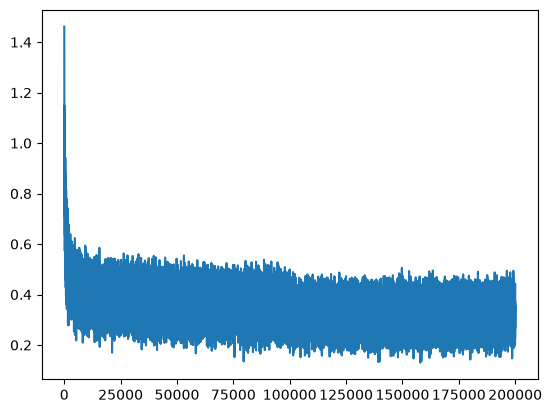

In [64]:
plt.plot(stepi, lossi)

In [65]:
emb = C[Xtr]  # (Ntr, 3, 10): all training examples, 3 chars, 10-dim embedding
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (Ntr, 200)
logits = h @ W2 + b2  # (Ntr, 27)
loss = F.cross_entropy(logits, Ytr)  # scalar: mean loss over the whole train split
loss


tensor(2.1331, grad_fn=<NllLossBackward0>)

In [66]:
emb = C[Xdev]  # (Ndev, 3, 10): all dev examples, 3 chars, 10-dim embedding
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (Ndev, 200)
logits = h @ W2 + b2  # (Ndev, 27)
loss = F.cross_entropy(logits, Ydev)  # scalar: mean loss over the dev split
loss


tensor(2.1706, grad_fn=<NllLossBackward0>)

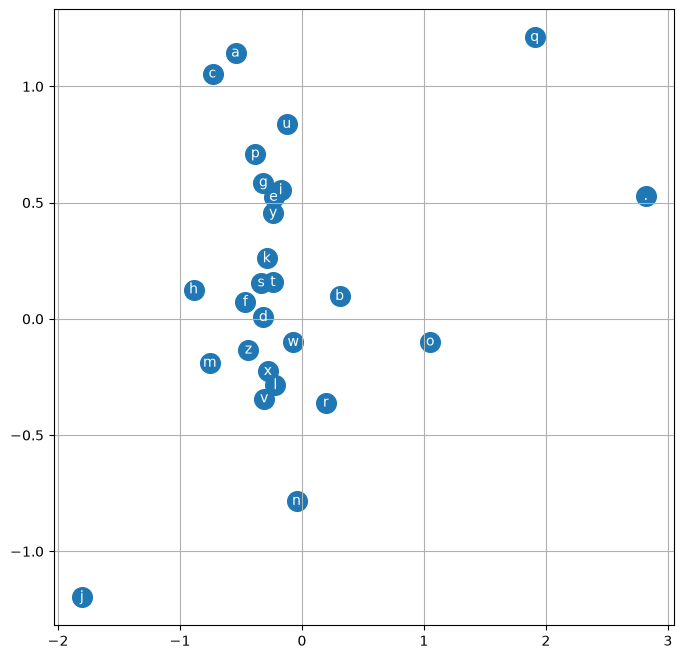

In [67]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [68]:
# training split, dev/validation split, test split
# 80%, 10%, 10%

In [72]:
context = [0] * block_size
torch.tensor([context]).shape

torch.Size([1, 3])

In [ ]:
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [70]:
# Sample 20 names from the trained model
g = torch.Generator().manual_seed(2147483647 + 10)  # fixed seed -> reproducible samples

for _ in range(20):
    
    out = []
    context = [0] * block_size  # start from all boundary tokens '.'
    while True:
      # C[context] -> (1, block_size, 10): embedding vectors for the 3 chars
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)  # (1, 200): flatten 3x10 -> 30
      logits = h @ W2 + b2  # (1, 27): unnormalized scores for the next char
      probs = F.softmax(logits, dim=1)  # probability distribution over 27 chars
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()  # sample next char
      context = context[1:] + [ix]  # slide window: drop oldest char, append new one
      out.append(ix)
      if ix == 0:  # sampled '.' means end of name
        break
    
    print(''.join(itos[i] for i in out))


carmah.
amelle.
khi.
mri.
revilvence.
salee.
hutnalee.
art.
kaeli.
nellara.
chaiiv.
kaleigh.
ham.
pory.
quint.
shon.
walianni.
watelogiearynix.
kaelynn.
abie.
